In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier,plot_tree,export_text
from sklearn.model_selection import train_test_split , KFold , LeaveOneOut , LeavePOut ,RepeatedKFold , StratifiedKFold,RepeatedStratifiedKFold , ShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score,recall_score,balanced_accuracy_score , cohen_kappa_score, precision_score, roc_auc_score,f1_score , roc_curve,auc
from sklearn.preprocessing import minmax_scale
from sklearn.neighbors import RadiusNeighborsClassifier

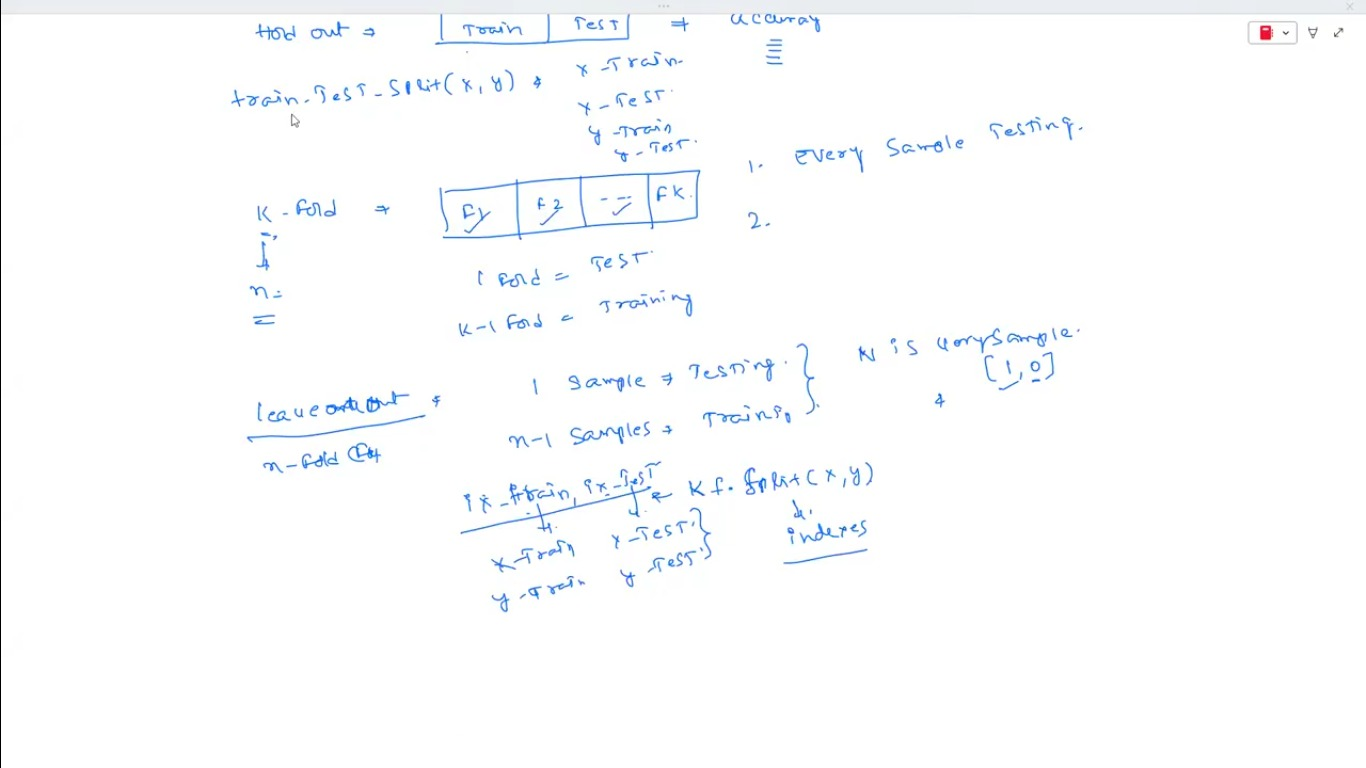

### Class notes: Hold-Out, K-Fold, Leave-One-Out

- **Hold-Out:** `train_test_split(X, y)` gives `X_train, X_test, y_train, y_test` and one accuracy score.
- **K-Fold:** folds F1 ... Fk. **1 fold = test, K-1 folds = training**. Advantage: every sample gets tested once.
- **Leave-One-Out (n-fold CV):** 1 sample = testing, n-1 samples = training, so **K = n**. Each fold's result is 1 or 0 (right or wrong).
- `ix_train, ix_test = kf.split(X, y)` gives **indexes**; use them to build `X_train, X_test, y_train, y_test`.

**Model selection map:** KFold, LeaveOneOut, LeavePOut | StratifiedKFold, RepeatedKFold, ShuffleSplit.
**Metrics (averaged over folds):** accuracy, balanced accuracy, Cohen's kappa, F1.

In [4]:
import os
path = 'data/fruits.csv' if os.path.exists('data/fruits.csv') else 'C:\\Users\\home\\Downloads\\fruits.csv'
df = pd.read_csv(path)
X = df[['sphericity','weight']]
y = df['label']

In [7]:
kf = KFold(n_splits=60,shuffle=True)
for ix_train ,ix_test in kf.split(X):
    print(ix_train)
    print(ix_test)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 49 50 51 52 53 54 55 56 57 58 59]
[48]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 51 52 53 54 55 56 57 58 59]
[50]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 48
 49 50 51 52 53 54 55 56 57 58 59]
[47]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[37]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[39]
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 

In [8]:
loo = LeaveOneOut()
for ix_train,ix_test in loo.split(X):
    print(ix_train)
    print(ix_test)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[0]
[ 0  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[1]
[ 0  1  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[2]
[ 0  1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[3]
[ 0  1  2  3  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59]
[4]
[ 0  1  2  3  4  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 2

In [16]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')

for ix_train, ix_test in loo.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
accuracy


[1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 0.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0,
 1.0]

In [17]:
bal_accuracy,f_measure

([1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0])

In [18]:
np.mean(accuracy),np.mean(bal_accuracy),np.mean(f_measure)

(np.float64(0.9666666666666667),
 np.float64(0.9666666666666667),
 np.float64(0.48333333333333334))

`LeavePOut(p=1)` is the same as `LeaveOneOut()`

In [22]:
lpo = LeavePOut(p=2)
for ix_train,ix_test in lpo.split(X):
    print(ix_train)
    print(ix_test)


[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59]
[0 1]
[ 1  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59]
[0 2]
[ 1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59]
[0 3]
[ 1  2  3  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59]
[0 4]
[ 1  2  3  4  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49
 50 51 52 53 54 55 56 57 58 59]
[0 5]
[ 1  2  3  4  5  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 

In [23]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')
lpo = LeavePOut(p=1)
for ix_train, ix_test in lpo.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

60

In [24]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')
lpo = LeavePOut(p=2)
for ix_train, ix_test in lpo.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

1770

In [25]:
np.mean(accuracy),np.mean(bal_accuracy),np.mean(f_measure)

(np.float64(0.965819209039548),
 np.float64(0.965819209039548),
 np.float64(0.7254237288135593))

In [26]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')
lpo = LeavePOut(p=3)
for ix_train, ix_test in lpo.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

KeyboardInterrupt: 

In [36]:
rkf = RepeatedKFold(n_splits=4,n_repeats=5)
for ix_train,ix_test in rkf.split(X):
    print(ix_train)
    print(ix_test)

[ 1  2  3  4  5  7  8  9 10 11 13 14 15 17 19 21 24 25 26 27 30 31 32 33
 34 37 38 39 40 41 43 44 45 46 47 48 49 51 52 54 55 56 57 58 59]
[ 0  6 12 16 18 20 22 23 28 29 35 36 42 50 53]
[ 0  1  2  4  5  6  8  9 10 12 13 16 17 18 20 22 23 27 28 29 30 31 33 35
 36 37 38 40 41 42 43 44 45 46 48 49 50 51 52 53 54 55 56 58 59]
[ 3  7 11 14 15 19 21 24 25 26 32 34 39 47 57]
[ 0  1  2  3  5  6  7 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 28
 29 30 31 32 34 35 36 37 38 39 40 42 46 47 48 49 50 52 53 55 57]
[ 4  8  9 10 27 33 41 43 44 45 51 54 56 58 59]
[ 0  3  4  6  7  8  9 10 11 12 14 15 16 18 19 20 21 22 23 24 25 26 27 28
 29 32 33 34 35 36 39 41 42 43 44 45 47 50 51 53 54 56 57 58 59]
[ 1  2  5 13 17 30 31 37 38 40 46 48 49 52 55]
[ 0  2  3  4  5  7  8 10 13 14 15 16 17 18 19 22 23 25 26 28 29 30 31 32
 33 34 35 36 37 39 40 41 42 43 44 45 47 50 51 52 54 55 56 58 59]
[ 1  6  9 11 12 20 21 24 27 38 46 48 49 53 57]
[ 1  2  4  5  6  7  9 11 12 15 16 18 19 20 21 22 24 25 26 27 28 29 30 31
 3

In [37]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')
rkf = RepeatedKFold(n_splits=4,n_repeats=5)
for ix_train, ix_test in rkf.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

20

In [38]:
np.mean(accuracy),np.mean(bal_accuracy),np.mean(f_measure)

(np.float64(0.9566666666666667),
 np.float64(0.9539276695526695),
 np.float64(0.9612889041642912))

In [41]:
kf = KFold(n_splits=3,shuffle=True)
for ix_train,ix_test in kf.split(X):
    print(y.iloc[ix_test].value_counts())
    

label
Orange    12
Apple      8
Name: count, dtype: int64
label
Apple     12
Orange     8
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64


In [46]:
skf = StratifiedKFold(n_splits=3,shuffle=True)
for ix_train,ix_test in skf.split(X,y):
    print(y.iloc[ix_test].value_counts())
    

label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64


In [50]:
rskf = RepeatedStratifiedKFold(n_splits=3,n_repeats=5)
for ix_train,ix_test in rskf.split(X,y):
    print(y.iloc[ix_test].value_counts())
    

label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64
label
Orange    10
Apple     10
Name: count, dtype: int64


In [52]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy')
rskf = RepeatedStratifiedKFold(n_splits=3,n_repeats=5)
for ix_train, ix_test in rskf.split(X,y):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

15

In [53]:
np.mean(accuracy),np.mean(bal_accuracy),np.mean(f_measure)

(np.float64(0.9666666666666665),
 np.float64(0.9666666666666665),
 np.float64(0.9665998329156225))

# Shuffle Split

Each split is an **independent random** train/test split, repeated `n_splits` times.

- `test_size` / `train_size` control the split sizes
- Test sets **can overlap** between splits, and some samples may never be tested (unlike K-Fold)
- Use `random_state` for reproducible results

In [ ]:
ss = ShuffleSplit(n_splits=5, test_size=0.25, random_state=42)
for ix_train, ix_test in ss.split(X):
    print(len(ix_train), len(ix_test))
    print(ix_test)

### Test sets overlap in Shuffle Split
Check how many samples are common between the test sets of the first two splits.

In [ ]:
splits = list(ss.split(X))
set(splits[0][1]).intersection(set(splits[1][1]))

### Evaluating a model with Shuffle Split

In [ ]:
accuracy = []
bal_accuracy = []
f_measure = []

model = DecisionTreeClassifier(criterion='entropy', random_state=10)
ss = ShuffleSplit(n_splits=10, test_size=0.25, random_state=42)

for ix_train, ix_test in ss.split(X):
    x_train, x_test, y_train, y_test = X.iloc[ix_train], X.iloc[ix_test], y.iloc[ix_train], y.iloc[ix_test]
    model.fit(x_train, y_train)
    y_predict = model.predict(x_test)
    accuracy.append(accuracy_score(y_test, y_predict))
    bal_accuracy.append(balanced_accuracy_score(y_test, y_predict))
    f_measure.append(f1_score(y_test, y_predict, pos_label='Orange'))
len(accuracy)

In [ ]:
np.mean(accuracy), np.mean(bal_accuracy), np.mean(f_measure)

**Note:** `StratifiedShuffleSplit` is the stratified version of Shuffle Split. It keeps the class ratio the same in every split, which is better for imbalanced classification data.

In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

sss = StratifiedShuffleSplit(n_splits=5, test_size=0.25, random_state=42)
for ix_train, ix_test in sss.split(X, y):
    print(y.iloc[ix_test].value_counts())

# Industry style and updated practice

| Data | Splitter |
|---|---|
| Imbalanced classification | `StratifiedKFold` |
| Several rows per patient/user | `GroupKFold` / `StratifiedGroupKFold` |
| Time series | `TimeSeriesSplit` (never shuffle) |
| Tuning + honest score | Nested CV (`GridSearchCV` inside `cross_val_score`) |

Always put scaling/encoding inside a `Pipeline`, set `random_state`, and report mean ± std.

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), DecisionTreeClassifier(criterion='entropy', random_state=42))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res = cross_validate(model, X, y, cv=cv,
                     scoring=['accuracy', 'balanced_accuracy', 'f1_macro'],
                     return_train_score=True)
for k, v in res.items():
    if k.startswith(('test_', 'train_')):
        print(f"{k:28s} {v.mean():.3f} ± {v.std():.3f}")

### Leave-One-Out the right way
With one test sample per fold, per-fold F1/balanced accuracy are meaningless. Collect all predictions, then score **once**.

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

y_pred = cross_val_predict(model, X, y, cv=LeaveOneOut())
print(classification_report(y, y_pred))

### `average` in F1 / precision / recall (multi-class)

| `average=` | Use when |
|---|---|
| `'binary'` | two classes, one positive class (`pos_label=`) |
| `'macro'` | all classes equally important |
| `'weighted'` | imbalanced, weight by class size |
| `'micro'` | pool all predictions